# 📘 Week 6 Practical and Revision Workbook

## Numerical Integration

This workbook connects the five Week 6 notebooks through runnable engineering
activities. Begin the guided A activities in Monday's workshop, continue the B problems
during Wednesday's practical, and finish the revision section at home.


# 🧭 Weekly workflow and expected effort

| Stage | Suggested use | Approximate time |
|---|---|---:|
| Before Monday | Run Notes 6.1–6.5 and record questions | 2 hours |
| Monday workshop | Guided Activities 1A–5A, demonstrations and discussion | 2 hours |
| Wednesday practical | Problem-solving Activities 1B–5B with tutor support | 2 hours |
| Revision | Finish problems and complete Activities 6–7 | 3 hours |

Every activity follows **Predict → Change or select → Run → Inspect → Explain
→ Validate**.

Monday does not require every A activity to be completed in full. The teaching team may
demonstrate selected cases, then ask you to finish the remaining comparisons before
Wednesday.


# ✅ Before Wednesday's practical

You should have:

- run the Week 6.1–6.5 notes from top to bottom;
- attempted each guided **A** activity at least once;
- written a prediction before changing each `TODO` value;
- saved or noted any figure you want to discuss; and
- reviewed the difference between a numerical estimate and physical truth.

All functions and datasets required for the B problems are supplied. The starter choices
run without errors, but they are not necessarily defensible answers.


# 🎯 Learning objectives

By completing this workbook, you should be able to:

- select trapezoidal, Simpson, Romberg or Gaussian integration for stated data;
- preserve coordinate values, ordering and units when integrating measurements;
- distinguish quadrature error from sensor bias and sampling limitations;
- use refinement and successive changes as evidence without claiming unknown truth;
- choose Gaussian order or composite panels under an evaluation budget;
- calculate two-dimensional resultants and centres of pressure; and
- justify an integration workflow using numerical, graphical and physical evidence.


# 📚 Week 6 notes map

| Workbook pair | Supporting notes | Main skill |
|---|---|---|
| 1A–1B | 6.1 Newton–Cotes Integration | Rule selection, coordinates and units |
| 2A–2B | 6.2 Errors in Newton–Cotes Methods | Bias, refinement and tolerance-based sampling |
| 3A–3B | 6.3 Richardson and Romberg | Leading-error cancellation and stopping evidence |
| 4A–4B | 6.4 Gaussian Quadrature | Node order, evaluation cost and composite panels |
| 5A–5B | 6.5 Multidimensional Integration | Resultants, centres of pressure and grid resolution |


# 🧰 Shared setup

Run the following cells before beginning any activity. They define deterministic teaching
models and reusable numerical functions. None of the generated signals represents
certified equipment data.


In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.polynomial.legendre import leggauss
from scipy.integrate import dblquad, fixed_quad, quad, simpson, trapezoid

pd.set_option("display.precision", 6)
plt.rcParams["figure.figsize"] = (8.5, 5.0)


def error_metrics(estimate, reference):
    signed = reference - estimate
    absolute = abs(signed)
    relative_percent = np.nan if np.isclose(reference, 0.0) else 100 * absolute / abs(reference)
    return signed, absolute, relative_percent


def underlying_flow_kg_s(time_s):
    time_s = np.asarray(time_s, dtype=float)
    duration_s = 12.0
    rise = 1.0 - np.exp(-1.5 * time_s)
    fall = 1.0 - np.exp(-1.25 * (duration_s - time_s))
    modulation = 1.0 + 0.06 * np.sin(1.15 * time_s)
    flow = 1.8 * rise * fall * modulation
    return np.where((time_s >= 0.0) & (time_s <= duration_s), flow, 0.0)


def brake_power_W(time_s):
    time_s = np.asarray(time_s, dtype=float)
    duration_s = 6.0
    power = (
        28_000.0
        * (1.0 - np.exp(-3.2 * time_s))
        * np.exp(-0.42 * time_s)
        * (1.0 + 0.045 * np.sin(2.1 * time_s))
    )
    return np.where((time_s >= 0.0) & (time_s <= duration_s), power, 0.0)


def heat_rate_W(time_s):
    time_s = np.asarray(time_s, dtype=float)
    return (
        420.0
        + 170.0 * np.exp(-((time_s - 7.0) / 2.1) ** 2)
        + 95.0 * np.exp(-((time_s - 15.5) / 1.5) ** 2)
        + 18.0 * np.sin(0.7 * time_s)
    )


FLOW_REFERENCE_KG, _ = quad(lambda t: float(underlying_flow_kg_s(t)), 0.0, 12.0)
BRAKE_ENERGY_REFERENCE_J, _ = quad(lambda t: float(brake_power_W(t)), 0.0, 6.0)
HEAT_REFERENCE_J, _ = quad(lambda t: float(heat_rate_W(t)), 0.0, 20.0)


In [ ]:
def romberg_table_from_samples(values, spacing):
    values = np.asarray(values, dtype=float)
    intervals = values.size - 1
    levels = int(np.log2(intervals))
    if intervals < 1 or 2**levels != intervals:
        raise ValueError("sample count must equal 2**k + 1")

    table = np.full((levels + 1, levels + 1), np.nan)
    for row in range(levels + 1):
        stride = 2 ** (levels - row)
        table[row, 0] = trapezoid(values[::stride], dx=spacing * stride)
        for column in range(1, row + 1):
            table[row, column] = table[row, column - 1] + (
                table[row, column - 1] - table[row - 1, column - 1]
            ) / (4.0**column - 1.0)
    return table


def mapped_legendre_rule(lower, upper, order):
    standard_nodes, standard_weights = leggauss(order)
    midpoint = 0.5 * (lower + upper)
    half_width = 0.5 * (upper - lower)
    return midpoint + half_width * standard_nodes, half_width * standard_weights


def composite_gauss(integrand, lower, upper, order, panels):
    boundaries = np.linspace(lower, upper, panels + 1)
    total = 0.0
    all_nodes = []
    all_weights = []
    for left, right in zip(boundaries[:-1], boundaries[1:]):
        nodes, weights = mapped_legendre_rule(left, right, order)
        total += np.sum(weights * integrand(nodes))
        all_nodes.extend(nodes)
        all_weights.extend(weights)
    return total, np.asarray(all_nodes), np.asarray(all_weights)


def integrate_sampled_field(x_coordinates, y_coordinates, values_yx):
    values_yx = np.asarray(values_yx, dtype=float)
    if values_yx.shape != (len(y_coordinates), len(x_coordinates)):
        raise ValueError("values must have shape (len(y), len(x))")
    strips = trapezoid(values_yx, x=x_coordinates, axis=1)
    return trapezoid(strips, x=y_coordinates, axis=0)


# 🟧 Monday workshop — guided exploration

Activities 1A–5A contain valid `TODO` values. Change one value at a time, predict the
effect before running, and record what the figure or table shows. The tutor may select a
subset for whole-class demonstration.


## Activity 1A — Sampling density and Newton–Cotes rule

A pump transfers liquid for 12 seconds. The known teaching model gives mass-flow rate in
kg/s. Change `TODO_SAMPLE_COUNT_1A` among `5`, `9`, `17`, `33` and `65`. Change
`TODO_METHOD_1A` between `"trapezoidal"` and `"simpson"`.

**Predict first:** which change will usually have the larger effect at coarse sampling—
doubling the sample count or changing the integration rule?


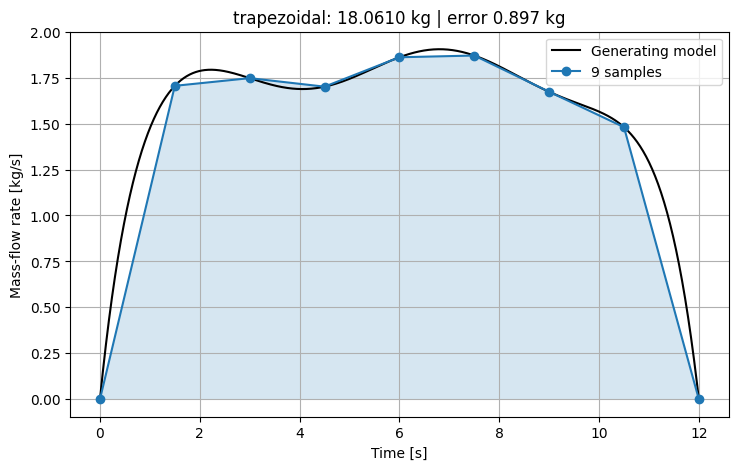

Relative quadrature error: 4.7325%


In [ ]:
TODO_SAMPLE_COUNT_1A = 9          # TODO: try 5, 9, 17, 33 and 65
TODO_METHOD_1A = "trapezoidal"    # TODO: use "trapezoidal" or "simpson"

time_1a = np.linspace(0.0, 12.0, TODO_SAMPLE_COUNT_1A)
flow_1a = underlying_flow_kg_s(time_1a)
if TODO_METHOD_1A == "trapezoidal":
    estimate_1a = trapezoid(flow_1a, x=time_1a)
elif TODO_METHOD_1A == "simpson":
    estimate_1a = simpson(flow_1a, x=time_1a)
else:
    raise ValueError("TODO_METHOD_1A must be 'trapezoidal' or 'simpson'")

_, absolute_error_1a, relative_error_1a = error_metrics(estimate_1a, FLOW_REFERENCE_KG)
time_dense_1a = np.linspace(0.0, 12.0, 1001)

fig, ax = plt.subplots()
ax.plot(time_dense_1a, underlying_flow_kg_s(time_dense_1a), color="black", label="Generating model")
ax.plot(time_1a, flow_1a, "o-", label=f"{TODO_SAMPLE_COUNT_1A} samples")
ax.fill_between(time_1a, 0.0, flow_1a, alpha=0.18)
ax.set(xlabel="Time [s]", ylabel="Mass-flow rate [kg/s]", title=f"{TODO_METHOD_1A}: {estimate_1a:.4f} kg | error {absolute_error_1a:.3g} kg")
ax.grid(True); ax.legend(); plt.show()

print(f"Relative quadrature error: {relative_error_1a:.4f}%")


## Activity 2A — Quadrature error versus sensor bias

A braking-power model is sampled over six seconds. Change `TODO_SAMPLE_COUNT_2A` among
`7`, `13`, `25`, `49` and `97`. Change `TODO_SENSOR_BIAS_PERCENT_2A` among `0`, `1` and
`3`.

**Predict first:** if sampling becomes extremely fine, which error can remain—quadrature
error or calibration bias?


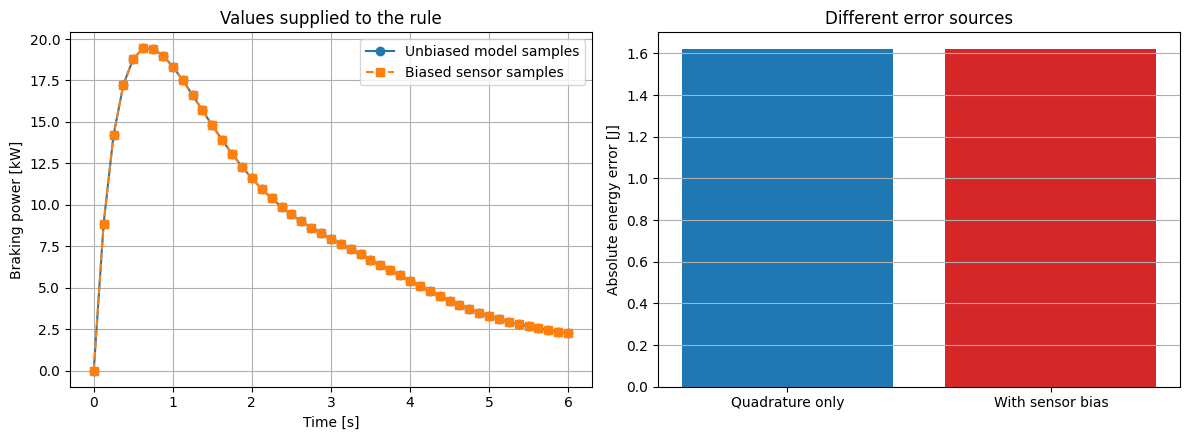

In [ ]:
TODO_SAMPLE_COUNT_2A = 49            # TODO: try 7, 13, 25, 49 and 97
TODO_SENSOR_BIAS_PERCENT_2A = 0     # TODO: try 0.0, 1.0 and 3.0

time_2a = np.linspace(0.0, 6.0, TODO_SAMPLE_COUNT_2A)
exact_samples_2a = brake_power_W(time_2a)
biased_samples_2a = exact_samples_2a * (1.0 + TODO_SENSOR_BIAS_PERCENT_2A / 100.0)

exact_sample_estimate_2a = simpson(exact_samples_2a, x=time_2a)
biased_estimate_2a = simpson(biased_samples_2a, x=time_2a)
quadrature_error_2a = abs(BRAKE_ENERGY_REFERENCE_J - exact_sample_estimate_2a)
total_error_2a = abs(BRAKE_ENERGY_REFERENCE_J - biased_estimate_2a)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(time_2a, exact_samples_2a / 1000, "o-", label="Unbiased model samples")
axes[0].plot(time_2a, biased_samples_2a / 1000, "s--", label="Biased sensor samples")
axes[0].set(xlabel="Time [s]", ylabel="Braking power [kW]", title="Values supplied to the rule")
axes[0].grid(True); axes[0].legend()
axes[1].bar(["Quadrature only", "With sensor bias"], [quadrature_error_2a, total_error_2a], color=["tab:blue", "tab:red"])
axes[1].set(ylabel="Absolute energy error [J]", title="Different error sources")
axes[1].grid(True, axis="y")
fig.tight_layout(); plt.show()


## Activity 3A — Richardson extrapolation and assumed order

For the trapezoidal approximation of $\int_0^1e^x\,\mathrm{d}x$, change
`TODO_FINE_LEVEL_3A` from `2` to `7`. Change `TODO_ASSUMED_ORDER_3A` among `1`, `2` and
`4`.

The fine grid has $2^k$ intervals, where $k$ is `TODO_FINE_LEVEL_3A`. The coarse grid has
half as many intervals. The expected trapezoidal leading order is $p=2$.

**Predict first:** does supplying a larger value of $p$ automatically produce a more
accurate result?


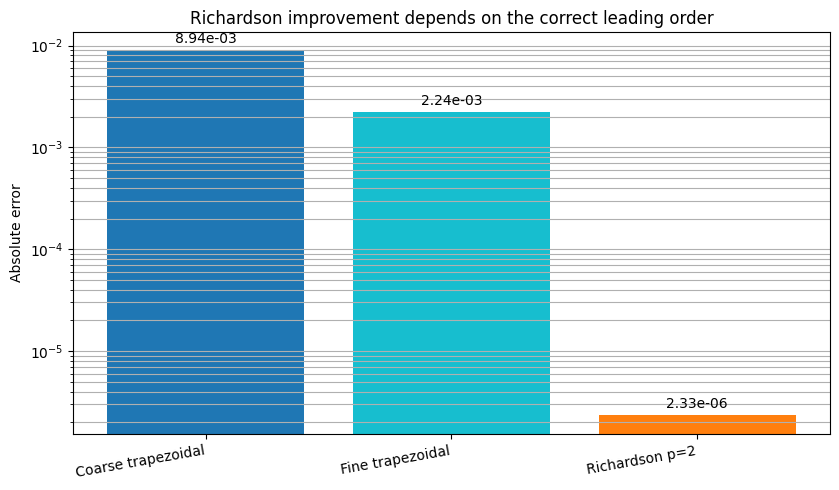

In [ ]:
TODO_FINE_LEVEL_3A = 3       # TODO: try levels 2 through 7
TODO_ASSUMED_ORDER_3A = 2    # TODO: try 1, 2 and 4

exact_3a = np.e - 1.0
fine_intervals_3a = 2 ** TODO_FINE_LEVEL_3A
coarse_intervals_3a = fine_intervals_3a // 2
x_coarse_3a = np.linspace(0.0, 1.0, coarse_intervals_3a + 1)
x_fine_3a = np.linspace(0.0, 1.0, fine_intervals_3a + 1)
coarse_3a = trapezoid(np.exp(x_coarse_3a), x=x_coarse_3a)
fine_3a = trapezoid(np.exp(x_fine_3a), x=x_fine_3a)
extrapolated_3a = fine_3a + (fine_3a - coarse_3a) / (2.0**TODO_ASSUMED_ORDER_3A - 1.0)

labels_3a = ["Coarse trapezoidal", "Fine trapezoidal", f"Richardson p={TODO_ASSUMED_ORDER_3A}"]
errors_3a = [abs(exact_3a - coarse_3a), abs(exact_3a - fine_3a), abs(exact_3a - extrapolated_3a)]
fig, ax = plt.subplots()
bars = ax.bar(labels_3a, errors_3a, color=["tab:blue", "tab:cyan", "tab:orange"])
ax.set_yscale("log"); ax.set_ylabel("Absolute error")
ax.set_title("Richardson improvement depends on the correct leading order")
ax.grid(True, axis="y", which="both"); ax.bar_label(bars, fmt="%.2e", padding=3)
plt.xticks(rotation=10, ha="right"); plt.tight_layout(); plt.show()


## Activity 4A — Gaussian nodes and order

A nonlinear elastomer seal is compressed from 0 to 0.06 m. Change `TODO_GAUSSIAN_ORDER_4A`
from `1` through `8`. Marker area represents mapped quadrature weight.

**Predict first:** how do the evaluation locations and work estimate change as order $n$
increases?


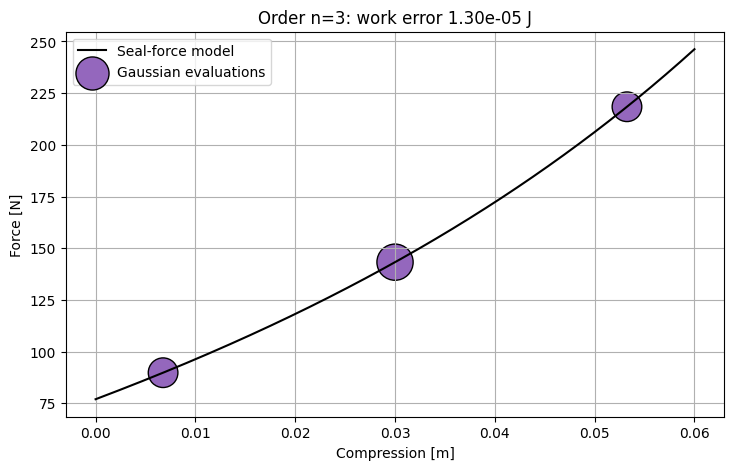

In [ ]:
def seal_force_N(displacement_m):
    displacement_m = np.asarray(displacement_m, dtype=float)
    return 35.0 + 900.0 * displacement_m + 42.0 * np.exp(22.0 * displacement_m)


SEAL_WORK_REFERENCE_J, _ = quad(lambda x: float(seal_force_N(x)), 0.0, 0.06)
TODO_GAUSSIAN_ORDER_4A = 3  # TODO: try orders 1 through 8

nodes_4a, weights_4a = mapped_legendre_rule(0.0, 0.06, TODO_GAUSSIAN_ORDER_4A)
estimate_4a = np.sum(weights_4a * seal_force_N(nodes_4a))
x_dense_4a = np.linspace(0.0, 0.06, 501)

fig, ax = plt.subplots()
ax.plot(x_dense_4a, seal_force_N(x_dense_4a), color="black", label="Seal-force model")
ax.scatter(nodes_4a, seal_force_N(nodes_4a), s=80 + 600 * weights_4a / weights_4a.max(), color="tab:purple", edgecolor="black", label="Gaussian evaluations")
ax.set(xlabel="Compression [m]", ylabel="Force [N]", title=f"Order n={TODO_GAUSSIAN_ORDER_4A}: work error {abs(SEAL_WORK_REFERENCE_J-estimate_4a):.2e} J")
ax.grid(True); ax.legend(); plt.show()


## Activity 5A — Pressure gradients and centre of pressure

Change `TODO_ALPHA_5A` and `TODO_BETA_5A` between `-0.5` and `0.8`. They control pressure
gradients in the $x$ and $y$ directions. The interaction coefficient remains fixed.

**Predict first:** which direction will the centre of pressure move when one coefficient
increases?


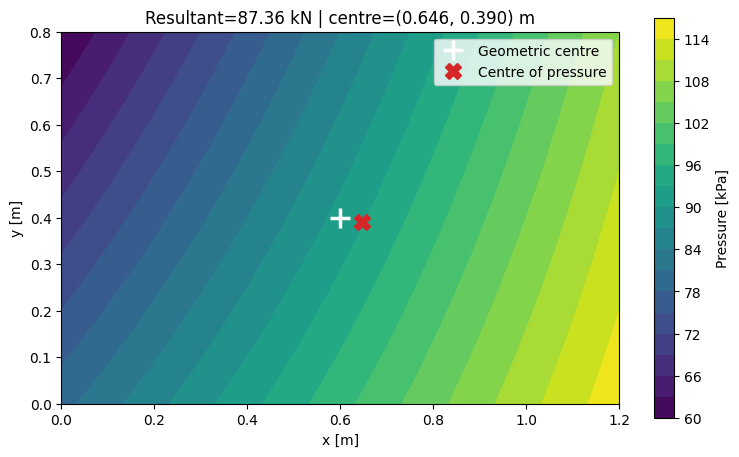

In [ ]:
TODO_ALPHA_5A = 0.45   # TODO: try values from -0.5 to 0.8
TODO_BETA_5A = -0.25   # TODO: try values from -0.5 to 0.8

plate_length_5a = 1.2
plate_height_5a = 0.8
pressure_reference_5a = 80_000.0
gamma_5a = 0.15


def pressure_field_5a(x_m, y_m, alpha=TODO_ALPHA_5A, beta=TODO_BETA_5A):
    return pressure_reference_5a * (
        1.0
        + alpha * x_m / plate_length_5a
        + beta * y_m / plate_height_5a
        + gamma_5a * x_m * y_m / (plate_length_5a * plate_height_5a)
    )


force_5a = pressure_reference_5a * plate_length_5a * plate_height_5a * (
    1.0 + TODO_ALPHA_5A / 2 + TODO_BETA_5A / 2 + gamma_5a / 4
)
moment_y_5a = pressure_reference_5a * plate_length_5a**2 * plate_height_5a * (
    0.5 + TODO_ALPHA_5A / 3 + TODO_BETA_5A / 4 + gamma_5a / 6
)
moment_x_5a = pressure_reference_5a * plate_length_5a * plate_height_5a**2 * (
    0.5 + TODO_ALPHA_5A / 4 + TODO_BETA_5A / 3 + gamma_5a / 6
)
x_cp_5a = moment_y_5a / force_5a
y_cp_5a = moment_x_5a / force_5a

x_5a = np.linspace(0.0, plate_length_5a, 151)
y_5a = np.linspace(0.0, plate_height_5a, 101)
X_5a, Y_5a = np.meshgrid(x_5a, y_5a, indexing="xy")

fig, ax = plt.subplots(figsize=(9, 5.2))
contour = ax.contourf(X_5a, Y_5a, pressure_field_5a(X_5a, Y_5a) / 1000, levels=18, cmap="viridis")
fig.colorbar(contour, ax=ax, label="Pressure [kPa]")
ax.plot(plate_length_5a/2, plate_height_5a/2, "+", markersize=14, markeredgewidth=2.5, color="white", label="Geometric centre")
ax.plot(x_cp_5a, y_cp_5a, "X", markersize=11, color="tab:red", label="Centre of pressure")
ax.set(xlabel="x [m]", ylabel="y [m]", title=f"Resultant={force_5a/1000:.2f} kN | centre=({x_cp_5a:.3f}, {y_cp_5a:.3f}) m")
ax.set_aspect("equal"); ax.legend(); plt.show()


# 🟩 Wednesday practical — problem solving

Activities 1B–5B provide data, candidate settings, helper functions and progressive hints.
Each starter choice produces a visualisation. Replace it with a defensible answer and
explain your evidence, units and limitations.


## Activity 1B — Integrate an irregular pump-test record

**Problem:** estimate the transferred liquid mass from an irregularly timed flow record.
Choose the coordinate treatment and integration rule. The data include small deterministic
measurement variation, so the generating function is not available during an ordinary
experiment. For this problem, do not use the synthetic reference defined for Activity 1A
to choose your rule; make the decision from the record and method assumptions.

**Choices supplied:**

- coordinate treatment: `"sample_index"` or `"actual_time"`;
- rule: `"trapezoidal"` or `"simpson"`.

**Hints:**

1. Inspect the spacing in `record_time_1b`.
2. Ask whether a sample index has units of seconds.
3. Prefer a rule whose assumptions are transparent for irregular measured data.
4. Report mass in kilograms and one limitation related to measurement quality.


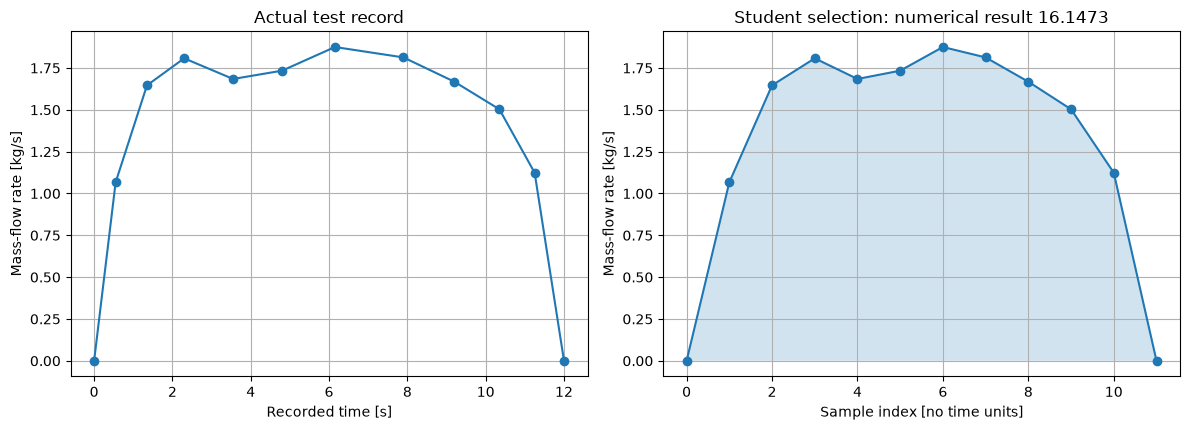

Student numerical result: 16.14729247737822


In [ ]:
record_time_1b = np.array([0.0, 0.55, 1.35, 2.3, 3.55, 4.8, 6.15, 7.9, 9.2, 10.35, 11.25, 12.0])
measurement_adjustment_1b = np.array([0.00, 0.02, -0.01, 0.015, -0.02, 0.01, 0.00, -0.012, 0.018, -0.01, 0.005, 0.00])
measured_flow_1b = underlying_flow_kg_s(record_time_1b) + measurement_adjustment_1b


def evaluate_transfer_1b(coordinate_choice, method_choice, plot_title):
    if coordinate_choice == "actual_time":
        coordinate = record_time_1b
        coordinate_label = "Actual time [s]"
    elif coordinate_choice == "sample_index":
        coordinate = np.arange(record_time_1b.size)
        coordinate_label = "Sample index [no time units]"
    else:
        raise ValueError("coordinate choice must be 'actual_time' or 'sample_index'")

    if method_choice == "trapezoidal":
        estimate = trapezoid(measured_flow_1b, x=coordinate)
    elif method_choice == "simpson":
        estimate = simpson(measured_flow_1b, x=coordinate)
    else:
        raise ValueError("method choice must be 'trapezoidal' or 'simpson'")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    axes[0].plot(record_time_1b, measured_flow_1b, "o-")
    axes[0].set(xlabel="Recorded time [s]", ylabel="Mass-flow rate [kg/s]", title="Actual test record")
    axes[0].grid(True)
    axes[1].plot(coordinate, measured_flow_1b, "o-")
    axes[1].fill_between(coordinate, 0.0, measured_flow_1b, alpha=0.2)
    axes[1].set(xlabel=coordinate_label, ylabel="Mass-flow rate [kg/s]", title=f"{plot_title}: numerical result {estimate:.4f}")
    axes[1].grid(True)
    fig.tight_layout(); plt.show()
    return estimate


selected_coordinates_1b = "sample_index"  # TODO: replace with a defensible choice
selected_method_1b = "simpson"             # TODO: replace and justify
student_mass_1b = evaluate_transfer_1b(selected_coordinates_1b, selected_method_1b, "Student selection")
print("Student numerical result:", student_mass_1b)


**Your answer:** state the coordinate treatment, rule, result with units, and one reason the
value is still not known physical truth.


## Activity 2B — Select a braking-energy sampling plan

**Problem:** choose the smallest supplied sample count and a rule that keep the synthetic
quadrature error at or below the stated tolerance. All candidate counts are odd, so
classical composite Simpson uses an even number of intervals.

**Hints:**

1. Filter the candidate table using `meets_tolerance`.
2. Sort eligible rows by `sample_count`, then compare methods.
3. The mathematical reference validates this teaching model only.
4. A real sampling plan must also address sensor bandwidth and calibration.


,method,sample_count,spacing_s,energy_J,absolute_error_J,meets_tolerance
0,trapezoidal,7,1.0000,47715.510679,6231.518060,False
1,simpson,7,1.0000,51526.160150,2420.868589,False
2,trapezoidal,13,0.5000,52163.468732,1783.560007,False
3,simpson,13,0.5000,53646.121417,300.907323,False
4,trapezoidal,25,0.2500,53483.046869,463.981871,False
5,simpson,25,0.2500,53922.906248,24.122492,False
6,trapezoidal,49,0.1250,53829.818357,117.210382,False
7,simpson,49,0.1250,53945.408854,1.619886,True
8,trapezoidal,97,0.0625,53917.648779,29.379961,False
9,simpson,97,0.0625,53946.925586,0.103153,True


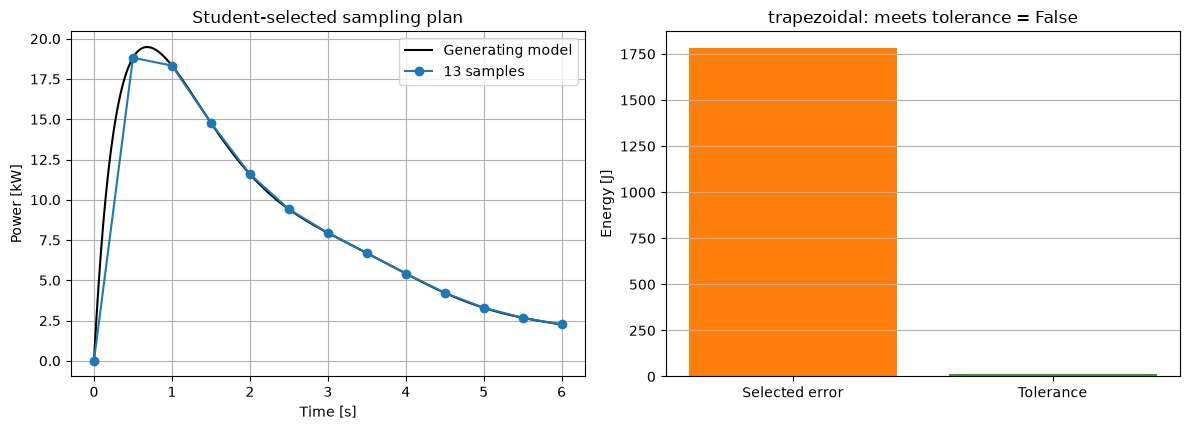

In [ ]:
ENERGY_TOLERANCE_J_2B = 15.0
candidate_counts_2b = [7, 13, 25, 49, 97]

candidate_rows_2b = []
for sample_count in candidate_counts_2b:
    times = np.linspace(0.0, 6.0, sample_count)
    powers = brake_power_W(times)
    for method, estimate in {
        "trapezoidal": trapezoid(powers, x=times),
        "simpson": simpson(powers, x=times),
    }.items():
        error = abs(BRAKE_ENERGY_REFERENCE_J - estimate)
        candidate_rows_2b.append({
            "method": method,
            "sample_count": sample_count,
            "spacing_s": times[1] - times[0],
            "energy_J": estimate,
            "absolute_error_J": error,
            "meets_tolerance": error <= ENERGY_TOLERANCE_J_2B,
        })
candidates_2b = pd.DataFrame(candidate_rows_2b)
display(candidates_2b)


def plot_sampling_plan_2b(method, sample_count, title):
    row = candidates_2b[(candidates_2b["method"] == method) & (candidates_2b["sample_count"] == sample_count)].iloc[0]
    times = np.linspace(0.0, 6.0, sample_count)
    powers = brake_power_W(times)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    dense = np.linspace(0.0, 6.0, 1001)
    axes[0].plot(dense, brake_power_W(dense)/1000, color="black", label="Generating model")
    axes[0].plot(times, powers/1000, "o-", label=f"{sample_count} samples")
    axes[0].set(xlabel="Time [s]", ylabel="Power [kW]", title=title)
    axes[0].grid(True); axes[0].legend()
    axes[1].bar(["Selected error", "Tolerance"], [row["absolute_error_J"], ENERGY_TOLERANCE_J_2B], color=["tab:orange", "tab:green"])
    axes[1].set(ylabel="Energy [J]", title=f"{method}: meets tolerance = {row['meets_tolerance']}")
    axes[1].grid(True, axis="y")
    fig.tight_layout(); plt.show()


selected_method_2b = "trapezoidal"  # TODO: replace after filtering
selected_count_2b = 13               # TODO: replace after filtering
plot_sampling_plan_2b(selected_method_2b, selected_count_2b, "Student-selected sampling plan")


**Your answer:** report the chosen rule, sample count, spacing, error and why this is the
least expensive supplied plan that meets the numerical requirement.


## Activity 3B — Select a Romberg stopping level

**Problem:** a callable heat-rate model has been evaluated on a nested 129-sample grid.
Choose the first Romberg diagonal level whose successive change meets the supplied combined
tolerance. During a real calculation, the ideal integral is unknown.

**Hints:**

1. Ignore level 0 because it has no previous diagonal value.
2. Filter the `criterion_met` column.
3. Choose the first eligible level, not the finest level automatically.
4. Call the successive change a convergence indicator, not exact error.


,level,samples,diagonal_estimate_J,successive_change_J,threshold_J,criterion_met
0,0,2,8578.451970,NaN,0.285785,False
1,1,3,8911.653855,333.201885,0.289117,False
2,2,5,9453.260820,541.606965,0.294533,False
3,3,9,9308.944534,144.316285,0.293089,False
4,4,17,9305.090832,3.853702,0.293051,False
5,5,33,9307.693774,2.602942,0.293077,False
6,6,65,9307.532833,0.160941,0.293075,True
7,7,129,9307.535336,0.002503,0.293075,True


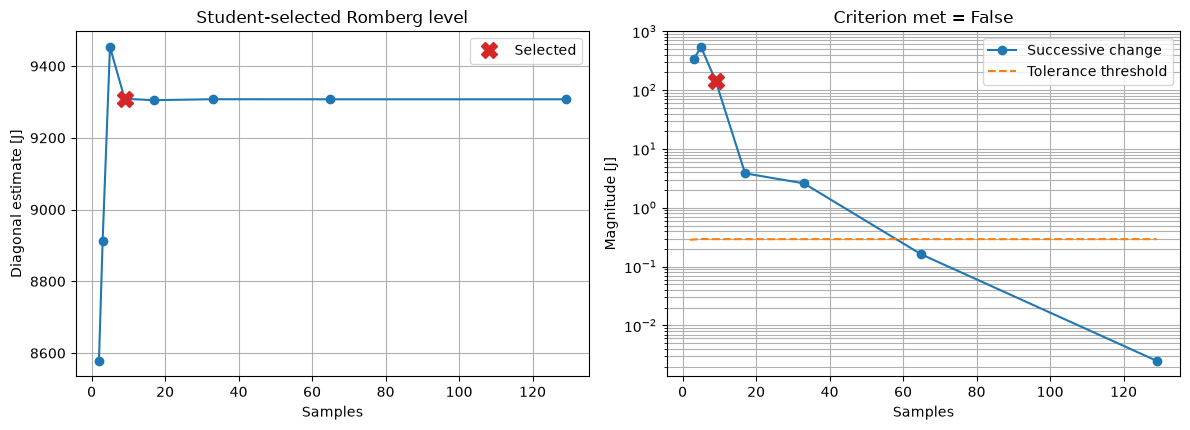

In [ ]:
time_3b = np.linspace(0.0, 20.0, 129)
heat_3b = heat_rate_W(time_3b)
table_3b = romberg_table_from_samples(heat_3b, time_3b[1] - time_3b[0])
diagonal_3b = np.diag(table_3b)
changes_3b = np.r_[np.nan, np.abs(np.diff(diagonal_3b))]
ABS_TOLERANCE_J_3B = 0.20
REL_TOLERANCE_3B = 1e-5
thresholds_3b = ABS_TOLERANCE_J_3B + REL_TOLERANCE_3B * np.abs(diagonal_3b)
levels_3b = pd.DataFrame({
    "level": np.arange(diagonal_3b.size),
    "samples": 2 ** np.arange(diagonal_3b.size) + 1,
    "diagonal_estimate_J": diagonal_3b,
    "successive_change_J": changes_3b,
    "threshold_J": thresholds_3b,
    "criterion_met": changes_3b <= thresholds_3b,
})
display(levels_3b)


def plot_romberg_choice_3b(selected_level, title):
    selected = levels_3b.loc[levels_3b["level"] == selected_level].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    axes[0].plot(levels_3b["samples"], levels_3b["diagonal_estimate_J"], "o-")
    axes[0].plot(selected["samples"], selected["diagonal_estimate_J"], "X", markersize=11, color="tab:red", label="Selected")
    axes[0].set(xlabel="Samples", ylabel="Diagonal estimate [J]", title=title)
    axes[0].grid(True); axes[0].legend()
    axes[1].semilogy(levels_3b["samples"], levels_3b["successive_change_J"], "o-", label="Successive change")
    axes[1].semilogy(levels_3b["samples"], levels_3b["threshold_J"], "--", label="Tolerance threshold")
    axes[1].plot(selected["samples"], selected["successive_change_J"], "X", markersize=11, color="tab:red")
    axes[1].set(xlabel="Samples", ylabel="Magnitude [J]", title=f"Criterion met = {selected['criterion_met']}")
    axes[1].grid(True, which="both"); axes[1].legend()
    fig.tight_layout(); plt.show()


selected_level_3b = 3  # TODO: replace with the first defensible level
plot_romberg_choice_3b(selected_level_3b, "Student-selected Romberg level")


**Your answer:** state the selected level, samples, estimate and successive change. Explain
why the criterion does not establish physical accuracy.


## Activity 4B — Select global or composite Gaussian quadrature

**Problem:** integrate a localised contact-load model over one metre. Select the candidate
with the fewest function evaluations that satisfies the stated work tolerance.

Candidate names beginning with `global` use one Gauss–Legendre panel. Candidate names
beginning with `composite` use a three-point rule on several equal panels.

**Hints:**

1. Filter using `meets_tolerance`.
2. Sort by `evaluations`, then by error.
3. Inspect whether the selected nodes resolve the narrow feature.
4. State that this workflow requires a callable model at selected locations.


,candidate,kind,order,panels,evaluations,estimate_J,absolute_error_J,meets_tolerance
0,global_n3,global,3,1,3,4.000000,2.605507,False
1,global_n5,global,5,1,5,5.389404,1.216103,False
2,global_n7,global,7,1,7,10.319693,3.714186,False
3,global_n9,global,9,1,9,4.437888,2.167619,False
4,global_n12,global,12,1,12,5.744723,0.860784,False
5,global_n16,global,16,1,16,7.352428,0.746920,False
6,composite_3x1,composite,3,1,3,4.000000,2.605507,False
7,composite_3x2,composite,3,2,6,8.476755,1.871247,False
8,composite_3x4,composite,3,4,12,7.095791,0.490284,True
9,composite_3x8,composite,3,8,24,6.478762,0.126745,True


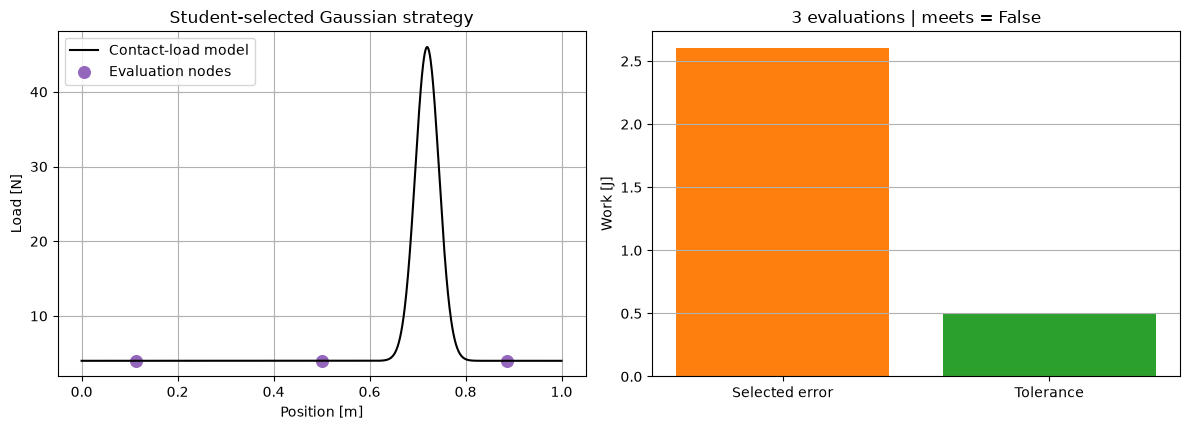

In [ ]:
def contact_load_N(position_m):
    position_m = np.asarray(position_m, dtype=float)
    return 4.0 + 42.0 * np.exp(-((position_m - 0.72) / 0.035) ** 2)


CONTACT_WORK_REFERENCE_J, _ = quad(lambda x: float(contact_load_N(x)), 0.0, 1.0, epsabs=1e-12)
CONTACT_TOLERANCE_J_4B = 0.50
candidate_specs_4b = {
    **{f"global_n{order}": ("global", order, 1) for order in [3, 5, 7, 9, 12, 16]},
    **{f"composite_3x{panels}": ("composite", 3, panels) for panels in [1, 2, 4, 8]},
}


def evaluate_candidate_4b(candidate_name):
    kind, order, panels = candidate_specs_4b[candidate_name]
    if kind == "global":
        nodes, weights = mapped_legendre_rule(0.0, 1.0, order)
        estimate = np.sum(weights * contact_load_N(nodes))
    else:
        estimate, nodes, weights = composite_gauss(contact_load_N, 0.0, 1.0, order, panels)
    return {
        "candidate": candidate_name,
        "kind": kind,
        "order": order,
        "panels": panels,
        "evaluations": len(nodes),
        "estimate_J": estimate,
        "absolute_error_J": abs(CONTACT_WORK_REFERENCE_J - estimate),
        "meets_tolerance": abs(CONTACT_WORK_REFERENCE_J - estimate) <= CONTACT_TOLERANCE_J_4B,
        "nodes": nodes,
        "weights": weights,
    }


candidate_results_4b = {name: evaluate_candidate_4b(name) for name in candidate_specs_4b}
candidate_table_4b = pd.DataFrame([
    {key: value for key, value in result.items() if key not in {"nodes", "weights"}}
    for result in candidate_results_4b.values()
])
display(candidate_table_4b)


def plot_candidate_4b(candidate_name, title):
    result = candidate_results_4b[candidate_name]
    x_dense = np.linspace(0.0, 1.0, 1201)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    axes[0].plot(x_dense, contact_load_N(x_dense), color="black", label="Contact-load model")
    axes[0].scatter(result["nodes"], contact_load_N(result["nodes"]), s=70, color="tab:purple", label="Evaluation nodes")
    axes[0].set(xlabel="Position [m]", ylabel="Load [N]", title=title)
    axes[0].grid(True); axes[0].legend()
    axes[1].bar(["Selected error", "Tolerance"], [result["absolute_error_J"], CONTACT_TOLERANCE_J_4B], color=["tab:orange", "tab:green"])
    axes[1].set(ylabel="Work [J]", title=f"{result['evaluations']} evaluations | meets = {result['meets_tolerance']}")
    axes[1].grid(True, axis="y")
    fig.tight_layout(); plt.show()


selected_candidate_4b = "global_n3"  # TODO: replace after comparing candidates
plot_candidate_4b(selected_candidate_4b, "Student-selected Gaussian strategy")


**Your answer:** report the candidate, evaluation count, result, error and why its node
pattern is suitable for the localised feature.


## Activity 5B — Select a pressure-grid resolution

**Problem:** a localised pressure field is available on several possible rectangular
measurement grids. Choose the grid with the fewest samples that satisfies both:

- resultant-force relative error at or below `0.1%`; and
- centre-of-pressure position error at or below `1 mm`.

**Hints:**

1. Filter candidates using both Boolean criteria.
2. Sort by total sample count.
3. Inspect whether the sample pattern resolves the local pressure feature.
4. Report the array shape as `(Ny, Nx)` and preserve both coordinate vectors.


,grid,Nx,Ny,samples,force_N,x_cp_m,y_cp_m,force_error_percent,cp_error_mm,force_ok,position_ok
0,7x5,7,5,35,72400.261934,0.628933,0.392696,0.241897,1.316524,False,False
1,13x9,13,9,117,72571.761510,0.628752,0.393689,0.005593,0.374803,True,True
2,25x17,25,17,425,72574.675350,0.628534,0.393866,0.001578,0.093286,True,True
3,49x33,49,33,1617,72575.529817,0.628480,0.393911,0.000401,0.023305,True,True


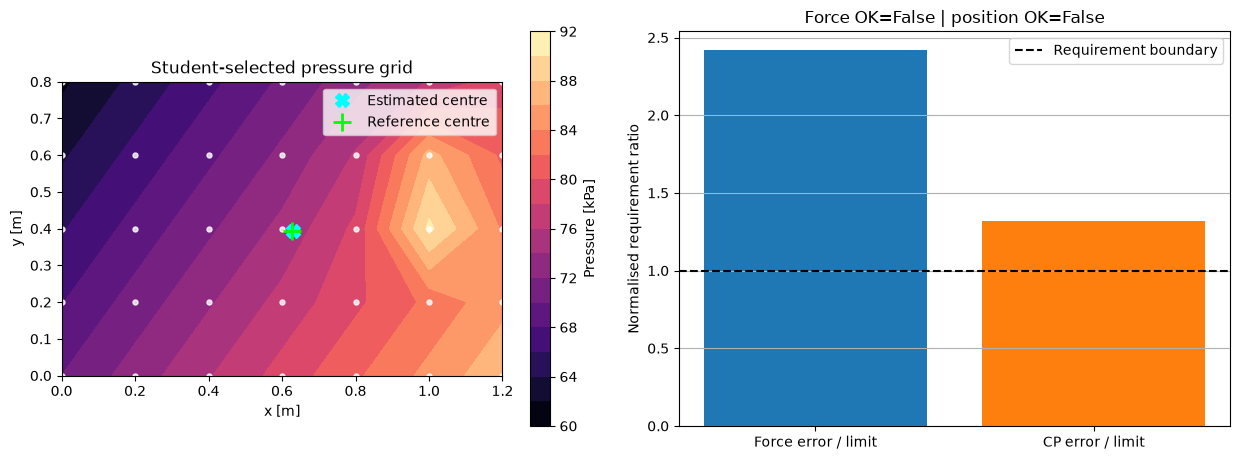

In [ ]:
plate_L_5b = 1.2
plate_H_5b = 0.8


def pressure_5b(x_m, y_m):
    base = 70_000.0 * (1.0 + 0.25 * x_m / plate_L_5b - 0.12 * y_m / plate_H_5b)
    local = 28_000.0 * np.exp(
        -((x_m - 0.82 * plate_L_5b) / (0.10 * plate_L_5b)) ** 2
        -((y_m - 0.62 * plate_H_5b) / (0.12 * plate_H_5b)) ** 2
    )
    return base + local


reference_force_5b, _ = dblquad(lambda y, x: pressure_5b(x, y), 0.0, plate_L_5b, 0.0, plate_H_5b)
reference_moment_y_5b, _ = dblquad(lambda y, x: x * pressure_5b(x, y), 0.0, plate_L_5b, 0.0, plate_H_5b)
reference_moment_x_5b, _ = dblquad(lambda y, x: y * pressure_5b(x, y), 0.0, plate_L_5b, 0.0, plate_H_5b)
reference_x_cp_5b = reference_moment_y_5b / reference_force_5b
reference_y_cp_5b = reference_moment_x_5b / reference_force_5b

grid_specs_5b = {"7x5": (7, 5), "13x9": (13, 9), "25x17": (25, 17), "49x33": (49, 33)}


def evaluate_grid_5b(grid_name):
    nx, ny = grid_specs_5b[grid_name]
    x = np.linspace(0.0, plate_L_5b, nx)
    y = np.linspace(0.0, plate_H_5b, ny)
    X, Y = np.meshgrid(x, y, indexing="xy")
    pressure = pressure_5b(X, Y)
    force = integrate_sampled_field(x, y, pressure)
    moment_y = integrate_sampled_field(x, y, X * pressure)
    moment_x = integrate_sampled_field(x, y, Y * pressure)
    x_cp = moment_y / force
    y_cp = moment_x / force
    force_error_percent = 100 * abs(force - reference_force_5b) / reference_force_5b
    cp_error_mm = 1000 * np.hypot(x_cp - reference_x_cp_5b, y_cp - reference_y_cp_5b)
    return {
        "grid": grid_name,
        "Nx": nx,
        "Ny": ny,
        "samples": nx * ny,
        "force_N": force,
        "x_cp_m": x_cp,
        "y_cp_m": y_cp,
        "force_error_percent": force_error_percent,
        "cp_error_mm": cp_error_mm,
        "force_ok": force_error_percent <= 0.1,
        "position_ok": cp_error_mm <= 1.0,
        "X": X,
        "Y": Y,
        "pressure": pressure,
    }


grid_results_5b = {name: evaluate_grid_5b(name) for name in grid_specs_5b}
grid_table_5b = pd.DataFrame([
    {key: value for key, value in result.items() if key not in {"X", "Y", "pressure"}}
    for result in grid_results_5b.values()
])
display(grid_table_5b)


def plot_grid_choice_5b(grid_name, title):
    result = grid_results_5b[grid_name]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.7))
    contour = axes[0].contourf(result["X"], result["Y"], result["pressure"] / 1000, levels=18, cmap="magma")
    fig.colorbar(contour, ax=axes[0], label="Pressure [kPa]")
    axes[0].scatter(result["X"], result["Y"], s=13, color="white", alpha=0.8)
    axes[0].plot(result["x_cp_m"], result["y_cp_m"], "X", color="cyan", markersize=10, label="Estimated centre")
    axes[0].plot(reference_x_cp_5b, reference_y_cp_5b, "+", color="lime", markersize=13, markeredgewidth=2, label="Reference centre")
    axes[0].set(xlabel="x [m]", ylabel="y [m]", title=title)
    axes[0].set_aspect("equal"); axes[0].legend()
    requirement_ratios = [result["force_error_percent"] / 0.1, result["cp_error_mm"] / 1.0]
    axes[1].bar(["Force error / limit", "CP error / limit"], requirement_ratios, color=["tab:blue", "tab:orange"])
    axes[1].axhline(1.0, color="black", linestyle="--", label="Requirement boundary")
    axes[1].set(ylabel="Normalised requirement ratio", title=f"Force OK={result['force_ok']} | position OK={result['position_ok']}")
    axes[1].grid(True, axis="y"); axes[1].legend()
    fig.tight_layout(); plt.show()


selected_grid_5b = "7x5"  # TODO: replace with the least expensive valid grid
plot_grid_choice_5b(selected_grid_5b, "Student-selected pressure grid")


**Your answer:** report the selected grid, array shape, sample count, force error and centre-
position error. Explain why a scalar force check alone is insufficient.


# ⬛ Revision and home study

Finish incomplete B activities before attempting the questions below. Answers should use
units, assumptions, numerical evidence and physical interpretation—not only method names.


## 📝 Activity 6 — Test-style short problems

1. Power is sampled at irregular times. Explain why integrating with only `dx=1` is unsafe.
2. Trapezoidal and Simpson estimates agree to six digits. Give two reasons the physical
   result may still be wrong.
3. Halving $h$ reduces trapezoidal error by approximately four. State the observed order.
4. A +2% force-sensor gain bias remains after grid refinement. Explain why.
5. Define the difference between an exact integral $I$ and a numerical estimate $Q(h)$.
6. In Richardson extrapolation, why must the leading order $p$ be justified?
7. A Romberg diagonal changes by 0.02 J. Why is 0.02 J not automatically the true error?
8. State the sample-count and spacing requirements of sampled-data Romberg integration.
9. A four-point Gauss–Legendre rule is exact through which polynomial degree?
10. Why can Gaussian quadrature be unsuitable for an already completed irregular experiment?
11. Pressure has units Pa and area has units m$^2$. Derive the units of its double integral.
12. `pressure_grid.shape == (9, 13)` was created with `indexing="xy"`. Identify the $x$ and
    $y$ array axes.
13. Why should integrating 1 over a two-dimensional domain be used as a validation check?
14. A tensor rule uses 6 nodes in each of four dimensions. Calculate its evaluation count.


## 🧪 Activity 7 — Integrated method-selection challenge

For each scenario, choose a starting method and give one validation check:

1. irregular experimental force–displacement samples;
2. a smooth callable spring model that is expensive to evaluate;
3. equally spaced power samples with count $2^k+1$ and strong smoothness evidence;
4. a callable pressure field over a triangular plate;
5. a complete temperature array on known rectangular $x$ and $y$ vectors;
6. a six-dimensional uncertainty integral with ten candidate nodes per direction.

Your answer must state what information is actually available, not only which method is
theoretically high order.


# 🔗 Project bridge

For a distributed quantity in one of the proposed project datasets, write a seven-line plan:

1. physical accumulated quantity;
2. integrand and units;
3. integration coordinates and bounds;
4. whether inputs are callable, gridded or scattered;
5. proposed numerical method;
6. refinement, geometry and physical validation checks; and
7. evidence that would make you reject the reported integral.


# ✅ Week 6 completion checklist

- [ ] I changed and explained every guided `TODO` in Activities 1A–5A.
- [ ] I completed and justified every problem in Activities 1B–5B.
- [ ] I preserved physical coordinates and units in sampled-data integration.
- [ ] I can separate quadrature error from sampling and measurement error.
- [ ] I can interpret refinement without claiming an unknown exact answer.
- [ ] I can explain Richardson, Romberg and Gaussian method requirements.
- [ ] I can calculate a pressure resultant and centre of pressure.
- [ ] I can identify coordinate and array-axis order in two dimensions.
- [ ] I completed Activities 6–7 without copying a solution.


# 📚 References and data provenance

Method definitions and APIs follow the official SciPy integration documentation and NumPy
array/grid documentation used in Notes 6.1–6.5.

All flow, braking, heat, seal, contact-load and pressure examples are synthetic,
deterministic and generated in code. They are designed to expose numerical behaviours and
are not measurements for engineering design.

# 🤖 AI acknowledgement

Generative AI assisted with drafting, code development and editorial review. Activities,
numerical behaviour and tutor solutions were checked for alignment with the Week 6 notes
and unit learning outcomes.
